# EDA: Predicting Airline Satisfaction

データを理解し、特徴量エンジニアリングの着想を得るための探索。結果の要約は、リポジトリのREADMEの「1. EDA」にある。

## 探索の流れ

- **全体像の確認:** 1節(数値)・2節(サービス評価)・3節(カテゴリ)・4節(欠損)・6節(単変量AUC)。ここで見つけた気になる点を、新しい仮説にした。
- **仮説1:** 「飛行距離の効き目は、出張・ビジネスクラスという客層の違いの表れでは?」(1・3節から)→ 5節で確認 → 飛行距離×座席クラスの満足率を特徴量にした。
- **仮説2:** 「Wi-Fiなどの0点は、最低評価ではなく『評価なし』では?」(2節から)→ 7節で確認 → 0点の意味が項目で違うと分かった(0点の印の特徴量は効かなかった)。
- **仮説3:** 「客層によって、評価の効き方が変わるのでは?」(特徴量エンジニアリングで、出張客だけに値を持たせる特徴量が効いたことから)→ 8節で確認 → 常連かつ出張客の快適さ(SHAPで1位)。

考察は、仮説を確かめた節(5・7・8節)は【仮説】【確認】【結果】【施策】、全体像の確認の節は「なぜ見たか・発見・新しい仮説」の形で書いた。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "Meiryo"  # 日本語ラベル用
train = pd.read_csv("data/train.csv")
TARGET = "satisfaction"
NUM = ["Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"]
CAT = ["Gender", "Customer Type", "Type of Travel", "Class"]
SVC = [c for c in train.columns if c not in NUM + CAT + ["id", TARGET]]  # サービス評価0〜5の13項目
LOG = {"Departure Delay in Minutes", "Arrival Delay in Minutes"}  # 約9割が0で潰れるため、遅延>0の行だけをlog1pで描く
PAL = {False: "#4C72B0", True: "#DD8452"}
print(train.shape, train[TARGET].mean())

(699635, 23) 0.44357272006117476


## 1. 数値変数 × 満足度(箱ひげ図・ヒストグラム)

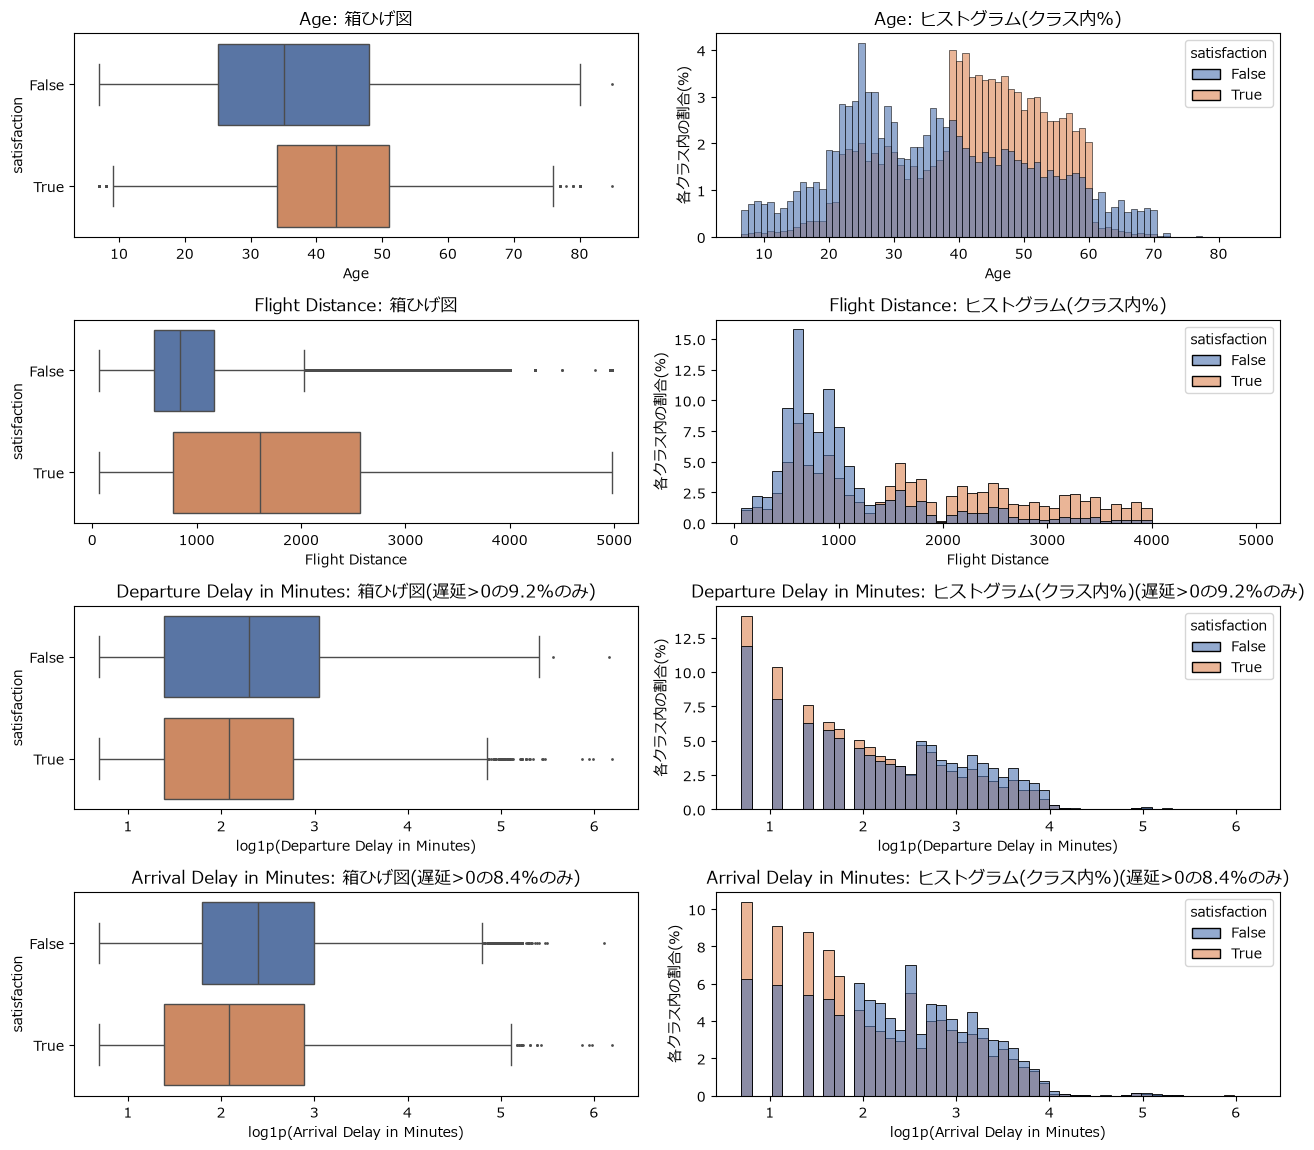

In [2]:
def box_hist(cols, discrete=()):
    """各変数について、左に満足度別の箱ひげ図、右に満足度別のヒストグラム(クラス内の割合)を並べる。"""
    fig, axes = plt.subplots(len(cols), 2, figsize=(13, 2.9 * len(cols)))
    for (ax_b, ax_h), c in zip(axes, cols):
        sub = train[train[c] > 0] if c in LOG else train
        x = np.log1p(sub[c]) if c in LOG else sub[c]
        label = f"log1p({c})" if c in LOG else c
        note = f"(遅延>0の{len(sub) / len(train):.1%}のみ)" if c in LOG else ""
        d = pd.DataFrame({label: x, TARGET: sub[TARGET]})
        disc = c in discrete
        sns.boxplot(data=d, x=label, y=TARGET, orient="h", order=[False, True],
                    hue=TARGET, palette=PAL, legend=False, ax=ax_b, fliersize=1)
        ax_b.set_title(f"{c}: 箱ひげ図{note}")
        # 満足/不満でサンプル数が違う(44%/56%)ので、各クラス内の割合で形を比べる
        sns.histplot(data=d, x=label, hue=TARGET, palette=PAL, stat="percent", common_norm=False,
                     discrete=disc, bins="auto" if disc else 50, multiple="dodge" if disc and c not in ("Age",) else "layer",
                     shrink=0.8 if disc and c != "Age" else 1, element="bars", alpha=0.6, ax=ax_h)
        ax_h.set_title(f"{c}: ヒストグラム(クラス内%){note}")
        ax_h.set_ylabel("各クラス内の割合(%)")
    fig.tight_layout()
    plt.show()

box_hist(NUM, discrete=("Age",))

#### 考察

**なぜ見たか:** 全体像の確認。数値の特徴量(年齢・飛行距離・遅延)と満足度の関係を一通り見る。

**見方:** 左=箱ひげ図(箱の線が中央値)、右=満足/不満それぞれの中での値の割合。2色の山がずれているほど、その変数だけで見分けやすい。

**発見**
- 飛行距離: 満足の中央値1,605・不満841。満足率は1,500付近を境に約30%→66〜77%と急に上がる(単変量AUC 0.696)。
- 年齢: 満足率は40〜60歳だけが約60%と高い山型(〜20歳16%、61歳〜14%)。
- 遅延: 約9割が0分。遅延が長いほど満足率は下がる(到着遅延0分45%→16〜60分31%)が、全体を分ける力は弱い(AUC約0.49)。

**新しい仮説:** 距離の急な変化は、「長距離便=出張でビジネスクラス」という客層の違いの表れではないか(→ 5節で確認)。

## 2. サービス評価(0〜5)× 満足度(箱ひげ図・ヒストグラム)

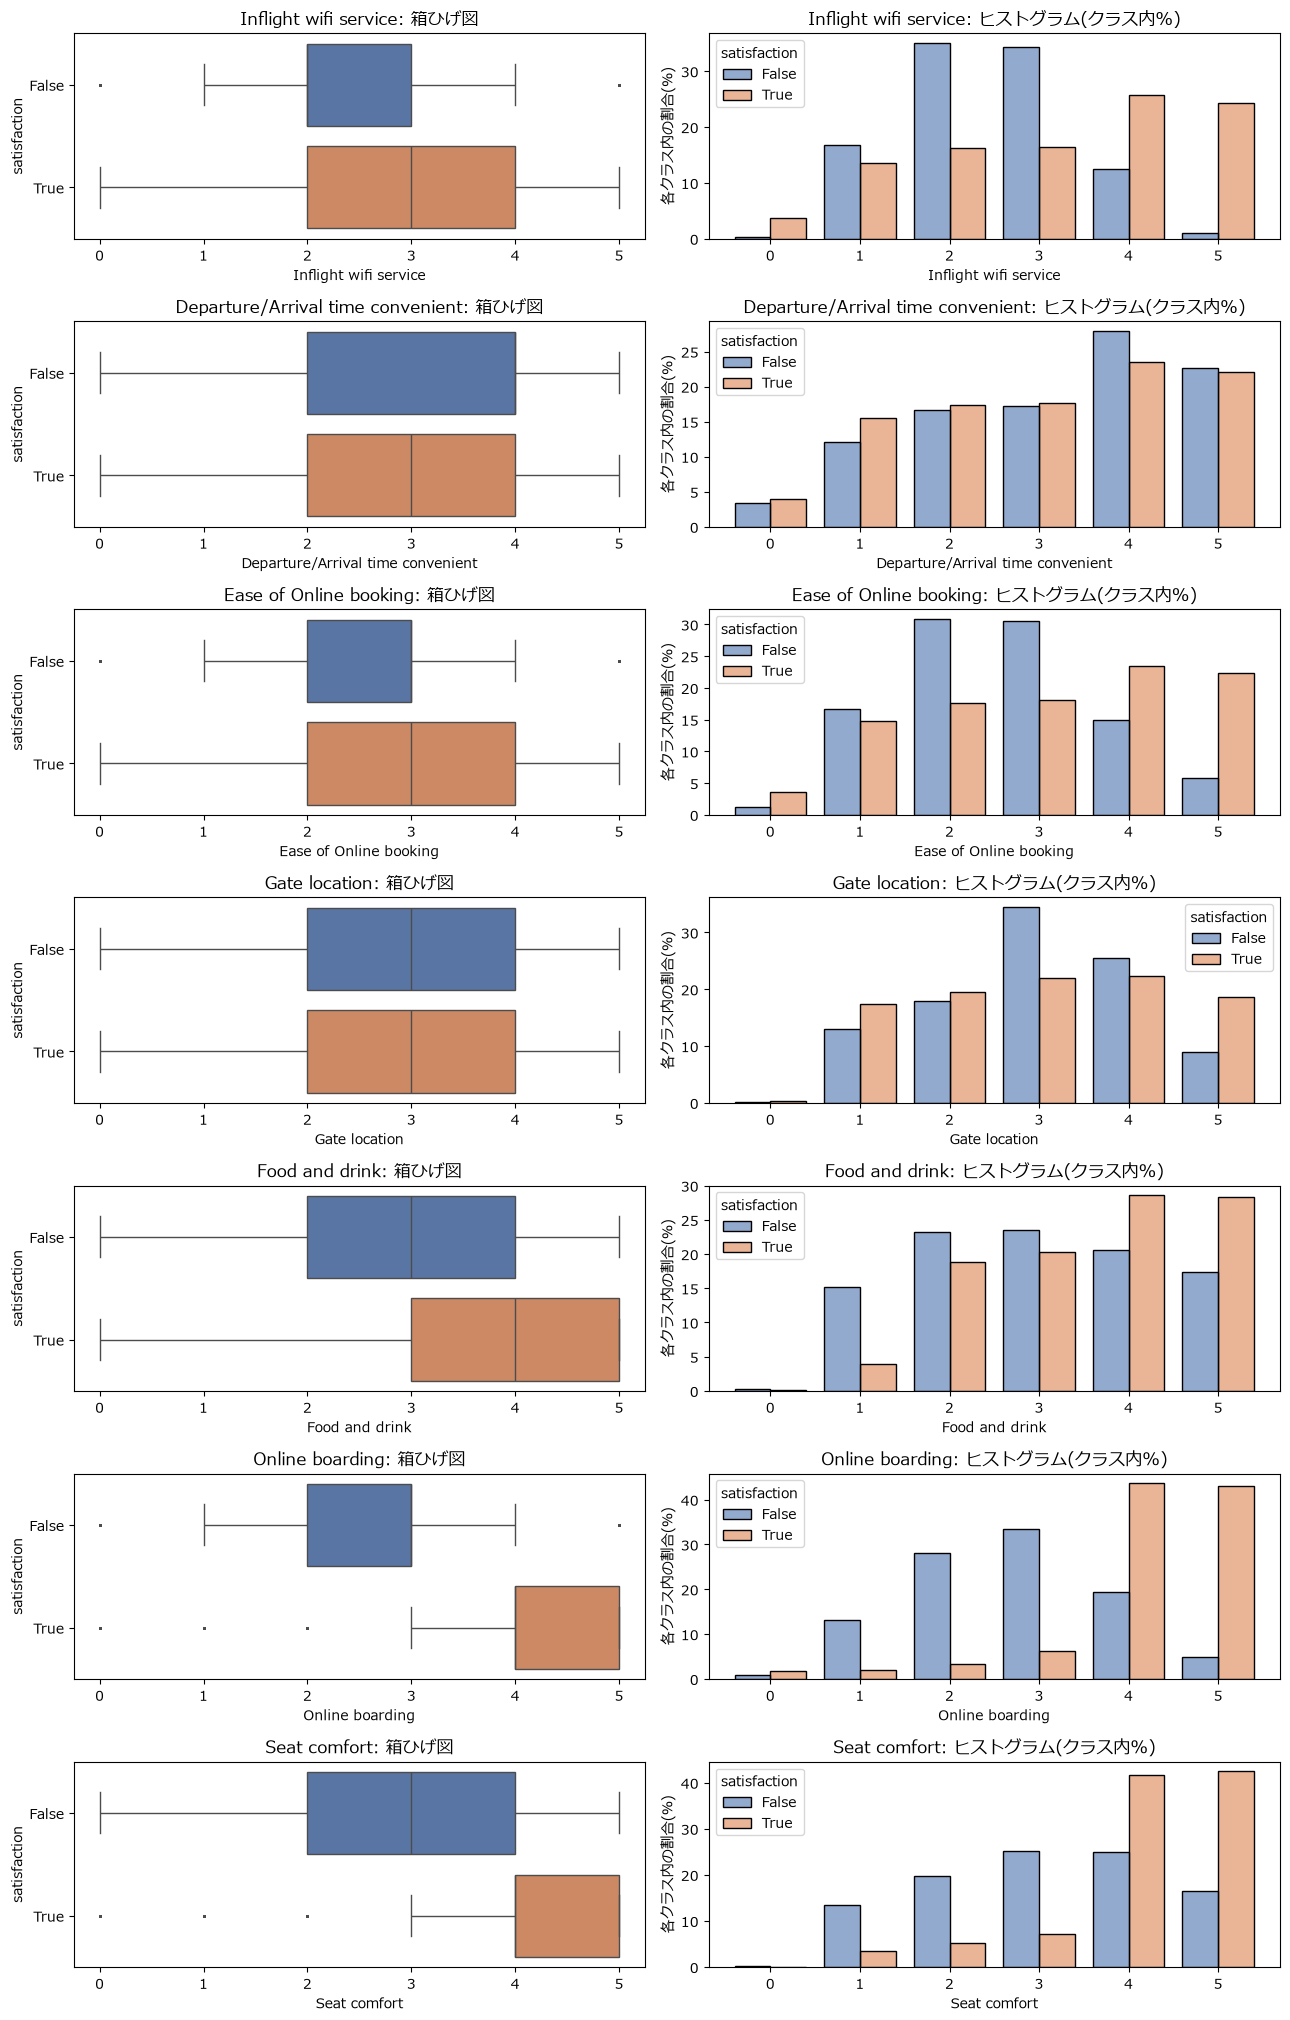

In [3]:
box_hist(SVC[:7], discrete=SVC)

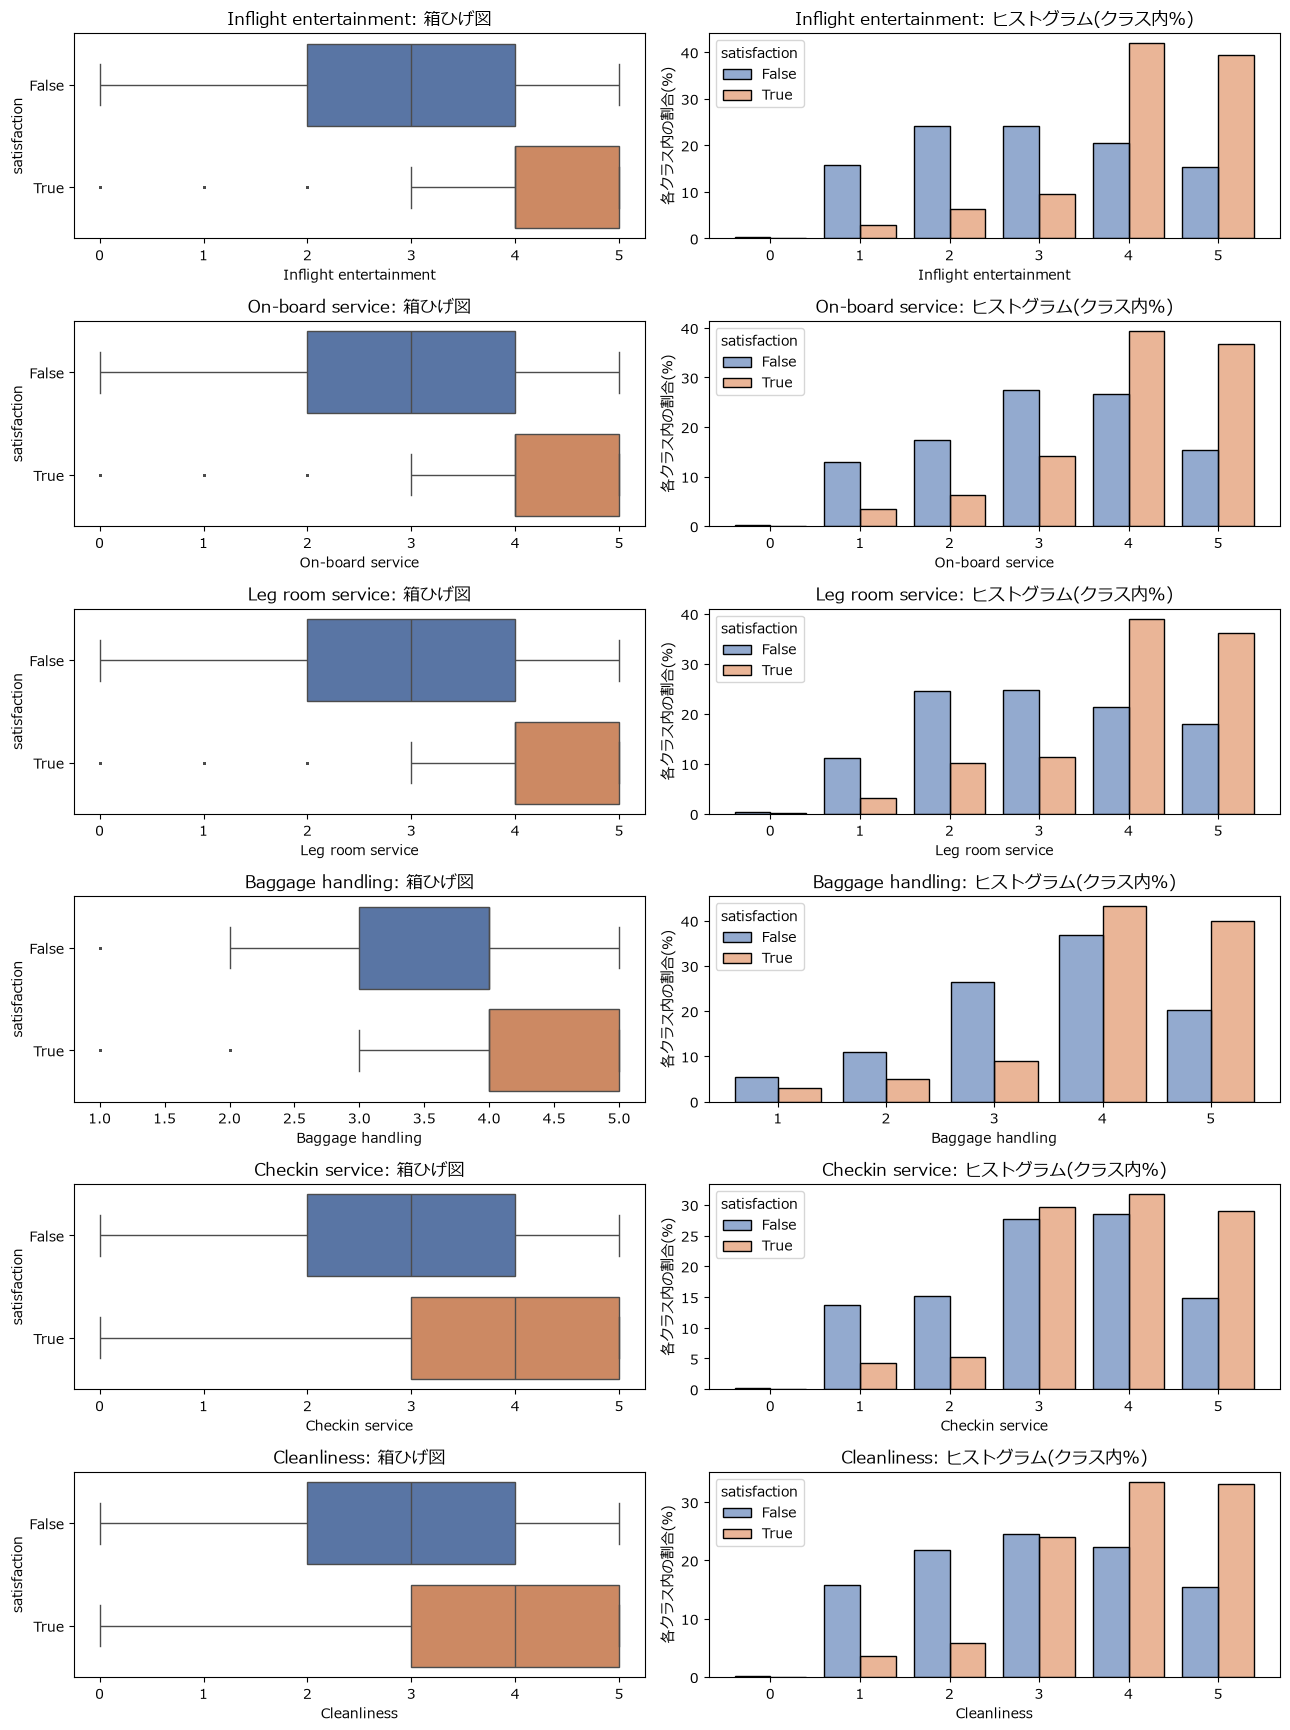

In [4]:
box_hist(SVC[7:], discrete=SVC)

#### 考察

**なぜ見たか:** 全体像の確認。サービス評価13項目のうち、どれが満足度と強く結びついているかを見る。

**見方:** 1節と同じ。評価は0〜5点。

**発見**
- 最も強いのはOnline boarding(AUC 0.840)。1〜3点の満足率は9〜13%だが、4点で64%、5点で88%に跳ね上がる。座席・機内エンタメ・清潔さなども「4点以上かどうか」の段差が大きい。
- Wi-Fi・オンライン予約は**U字型**: Wi-Fiの満足率は0点89%、1点39%、2〜3点27%、5点95%。0点は低評価ではない可能性がある。
- 出発・到着時刻の便利さだけは、評価が高いほど満足率がわずかに下がる(AUC 0.473)。

**新しい仮説:** Wi-Fi・オンライン予約の0点は、最低評価ではなく「使っていない(評価なし)」ではないか(→ 7節で確認)。

## 3. カテゴリ変数 × 満足度(件数・満足率)

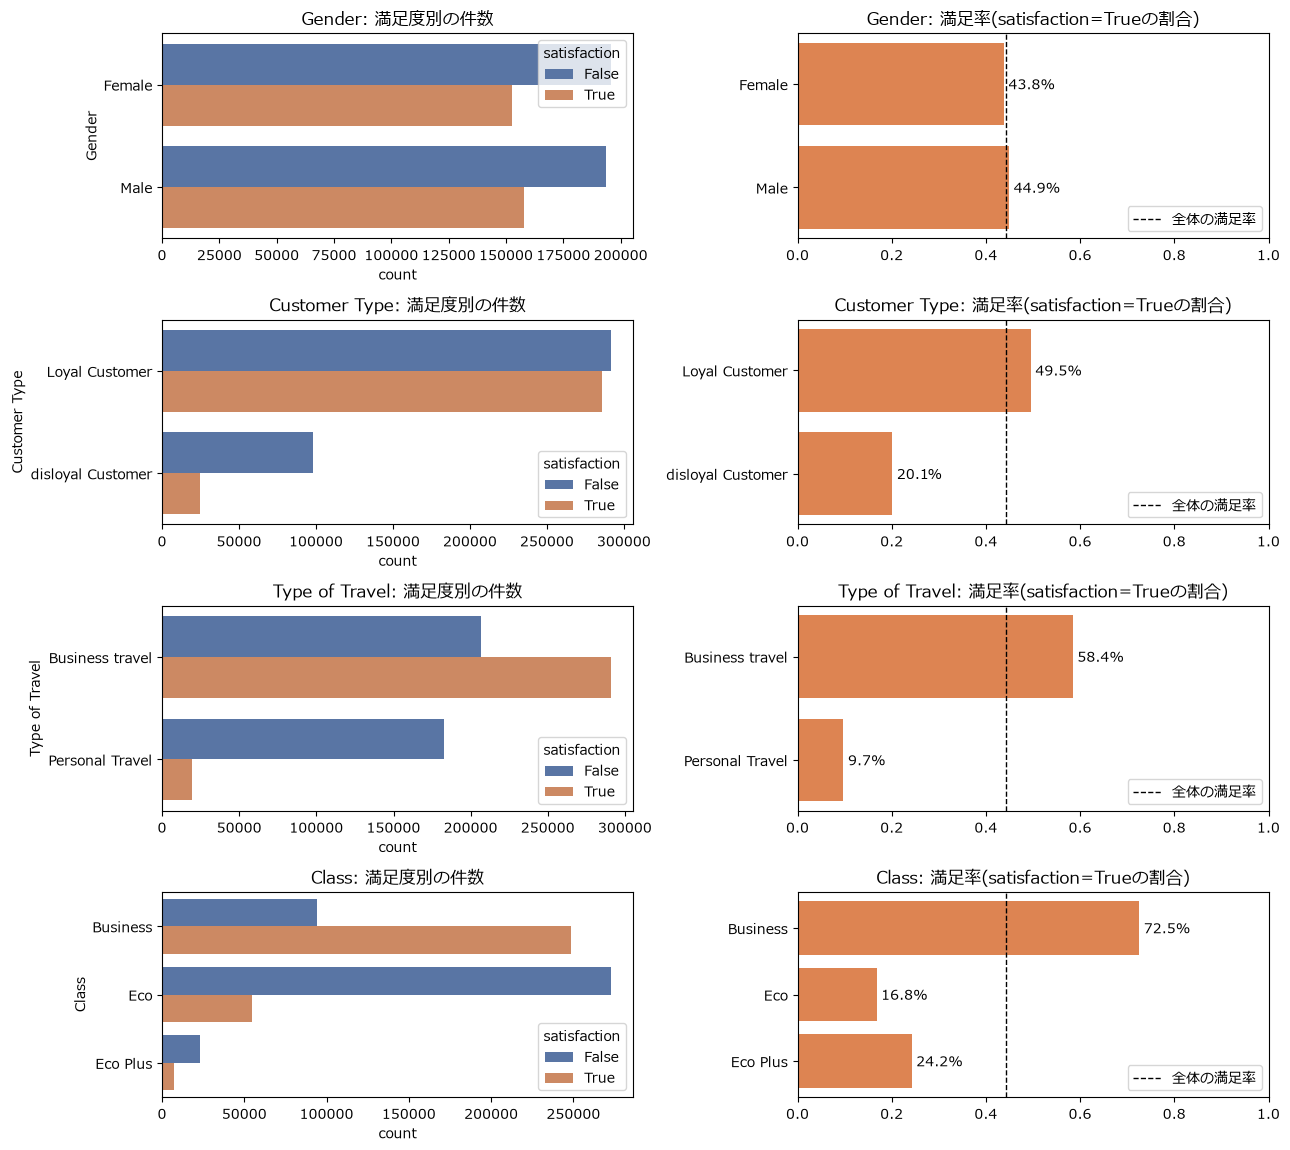

In [5]:
# カテゴリ変数は数値でないため箱ひげ図は描けない。代わりに満足度別の件数(ヒストグラム相当)と満足率を並べる
fig, axes = plt.subplots(len(CAT), 2, figsize=(13, 2.9 * len(CAT)))
for (ax_c, ax_r), c in zip(axes, CAT):
    order = sorted(train[c].unique())
    sns.countplot(data=train, y=c, hue=TARGET, palette=PAL, order=order, ax=ax_c)
    ax_c.set_title(f"{c}: 満足度別の件数")
    rate = train.groupby(c)[TARGET].mean().reindex(order)
    ax_r.barh(order, rate.values, color="#DD8452")
    ax_r.axvline(train[TARGET].mean(), color="k", ls="--", lw=1, label="全体の満足率")
    for i, v in enumerate(rate.values):
        ax_r.text(v + 0.01, i, f"{v:.1%}", va="center")
    ax_r.set_xlim(0, 1); ax_r.invert_yaxis(); ax_r.legend(loc="lower right")
    ax_r.set_title(f"{c}: 満足率(satisfaction=Trueの割合)")
fig.tight_layout()
plt.show()

#### 考察

**なぜ見たか:** 全体像の確認。カテゴリの特徴量(座席クラス・旅行目的・顧客区分・性別)ごとの満足率の差を見る。

**見方:** 左=カテゴリごとの件数、右=満足率(点線は全体の44.4%)。

**発見**
- 座席クラス: Business 72.5%、Eco 16.8%、Eco Plus 24.2%。旅行目的: 出張58.4%、私用9.7%。常連49.5%、非常連20.1%。性別はほぼ差なし。

**新しい仮説:** ビジネスクラス・出張・長距離便は、同じ客層が重なっているのではないか(→ 5節で確認)。

## 4. 欠損値の確認

                          train  test
Arrival Delay in Minutes    292   130


空文字: {'Gender': 0, 'Customer Type': 0, 'Type of Travel': 0, 'Class': 0}


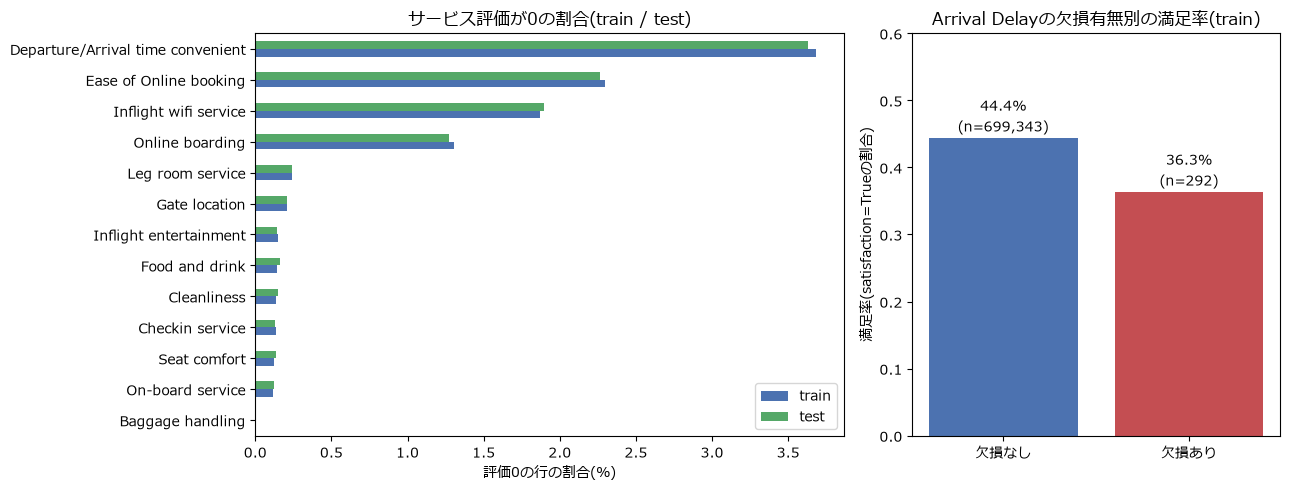

In [6]:
test = pd.read_csv("data/test.csv")
# NaN(本当の欠損)の件数。空文字の混入も確認する
miss = pd.DataFrame({"train": train.isna().sum(), "test": test.isna().sum()}).fillna(0).astype(int)
print(miss[miss.sum(axis=1) > 0])
print("空文字:", {c: int((d[c].astype(str).str.strip() == "").sum()) for d in (train, test) for c in CAT})

# サービス評価の0は「未回答・該当なし」の実質的な欠損の可能性があるため、NaNと並べて確認する
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.6, 1]})
z = pd.DataFrame({"train": (train[SVC] == 0).mean() * 100, "test": (test[SVC] == 0).mean() * 100})
z.sort_values("train").plot.barh(ax=ax0, color=["#4C72B0", "#55A868"])
ax0.set_xlabel("評価0の行の割合(%)"); ax0.set_title("サービス評価が0の割合(train / test)")

na = train["Arrival Delay in Minutes"].isna()
rate = train.groupby(na.map({True: "欠損あり", False: "欠損なし"}))[TARGET].agg(["mean", "size"]).loc[["欠損なし", "欠損あり"]]
ax1.bar(rate.index, rate["mean"], color=["#4C72B0", "#C44E52"])
for i, (m, n) in enumerate(rate.values):
    ax1.text(i, m + 0.01, f"{m:.1%}\n(n={int(n):,})", ha="center")
ax1.set_ylim(0, 0.6); ax1.set_ylabel("満足率(satisfaction=Trueの割合)")
ax1.set_title("Arrival Delayの欠損有無別の満足率(train)")
fig.tight_layout()
plt.show()

#### 考察

**なぜ見たか:** 全体像の確認。欠損の有無と、補完が必要かを決める。2節で気になった評価「0点」の多さもあわせて見る。

**発見**
- 本当の欠損は到着遅延の292行(0.04%)だけ。木のモデルは欠損をそのまま扱えるので、補完はしない。
- 影響が大きいのはサービス評価の「0点」の方。いずれかの評価が0の行は6.4%あり、trainとtestで割合が同じ。

## 5. Class × Type of Travel のクロス集計

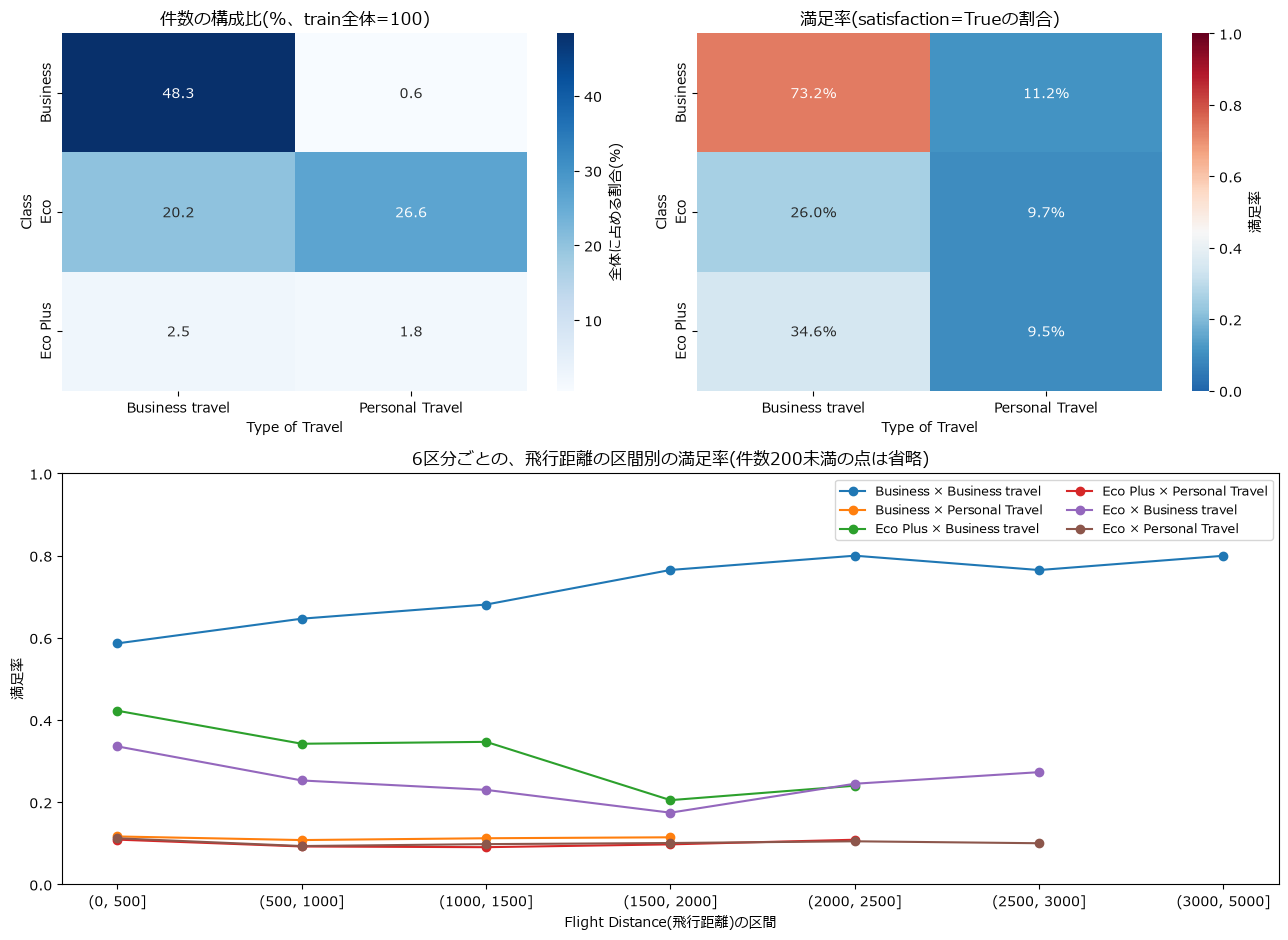

In [7]:
# Class(座席クラス)× Type of Travel(旅行目的)の6区分ごとに、件数の構成比と満足率を並べる
fig = plt.figure(figsize=(13, 9.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15])
ax_n, ax_r, ax_d = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])
share = pd.crosstab(train["Class"], train["Type of Travel"], normalize=True) * 100
rate = pd.crosstab(train["Class"], train["Type of Travel"], values=train[TARGET], aggfunc="mean")
sns.heatmap(share, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "全体に占める割合(%)"}, ax=ax_n)
ax_n.set_title("件数の構成比(%、train全体=100)")
sns.heatmap(rate, annot=True, fmt=".1%", cmap="RdBu_r", center=train[TARGET].mean(), vmin=0, vmax=1,
            cbar_kws={"label": "満足率"}, ax=ax_r)
ax_r.set_title("満足率(satisfaction=Trueの割合)")

# 1節で見えた「長距離ほど満足」が、6区分の中でも成り立つかを確認する
bins = [0, 500, 1000, 1500, 2000, 2500, 3000, 5000]
d = train.assign(dist=pd.cut(train["Flight Distance"], bins), seg=train["Class"] + " × " + train["Type of Travel"])
line = d.groupby(["seg", "dist"], observed=True)[TARGET].agg(["mean", "size"]).reset_index()
line = line[line["size"] >= 200]  # 件数が少なく揺れの大きい点は描かない
for seg, g in line.groupby("seg"):
    ax_d.plot(g["dist"].astype(str), g["mean"], marker="o", label=seg)
ax_d.set_xlabel("Flight Distance(飛行距離)の区間"); ax_d.set_ylabel("満足率"); ax_d.set_ylim(0, 1)
ax_d.set_title("6区分ごとの、飛行距離の区間別の満足率(件数200未満の点は省略)")
ax_d.legend(fontsize=9, ncol=2)
fig.tight_layout()
plt.show()

#### 考察

**【仮説】** 1節で満足率が飛行距離1,500付近で急に上がり、3節で座席クラス・旅行目的の差も大きかった。「長距離便=出張でビジネスクラス」という客層の違いが、飛行距離の効き目として見えているのではないか。

**【確認】** 座席クラス×旅行目的の6区分で、人数・満足率と、飛行距離の区間ごとの満足率を見る。
上段左=6区分の人数の割合、上段右=満足率(赤いほど高い)。下段=飛行距離の区間ごとの満足率(線1本が1区分)。

**【結果】**
- 満足率が高いのは「出張でビジネスクラス」(73.2%)だけ。私用旅行はクラスに関係なく9.5〜11.2%。
- 仮説どおり、飛行距離の効き目の多くは客層の違いの表れ。全体の単変量AUC 0.696が、6区分の中では0.44〜0.59に下がる。エコノミーの出張客では、逆に長距離ほど満足率が下がる。

**【施策】** 飛行距離×座席クラスごとの満足率を特徴量にした(採用、改善は+0.000060と小さい)。なお、飛行距離そのものは値ごとの満足率(Target Encoding)が最大の改善になったが、これはEDAではなく、学習前の事前確認から着想した。

## 6. 特徴量ごとの単変量AUC

                                     raw   rate
feature                                        
Online boarding                    0.840  0.854
Class                                NaN  0.782
Inflight entertainment             0.745  0.745
Inflight wifi service              0.663  0.736
Seat comfort                       0.732  0.732
Flight Distance                    0.696  0.710
Type of Travel                       NaN  0.703
On-board service                   0.699  0.699
Cleanliness                        0.689  0.689
Leg room service                   0.688  0.688
Age                                0.624  0.685
Ease of Online booking             0.609  0.666
Baggage handling                   0.655  0.662
Checkin service                    0.636  0.636
Food and drink                     0.621  0.621
Gate location                      0.514  0.604
Customer Type                        NaN  0.586
Departure/Arrival time convenient  0.473  0.536
Arrival Delay in Minutes           0.484

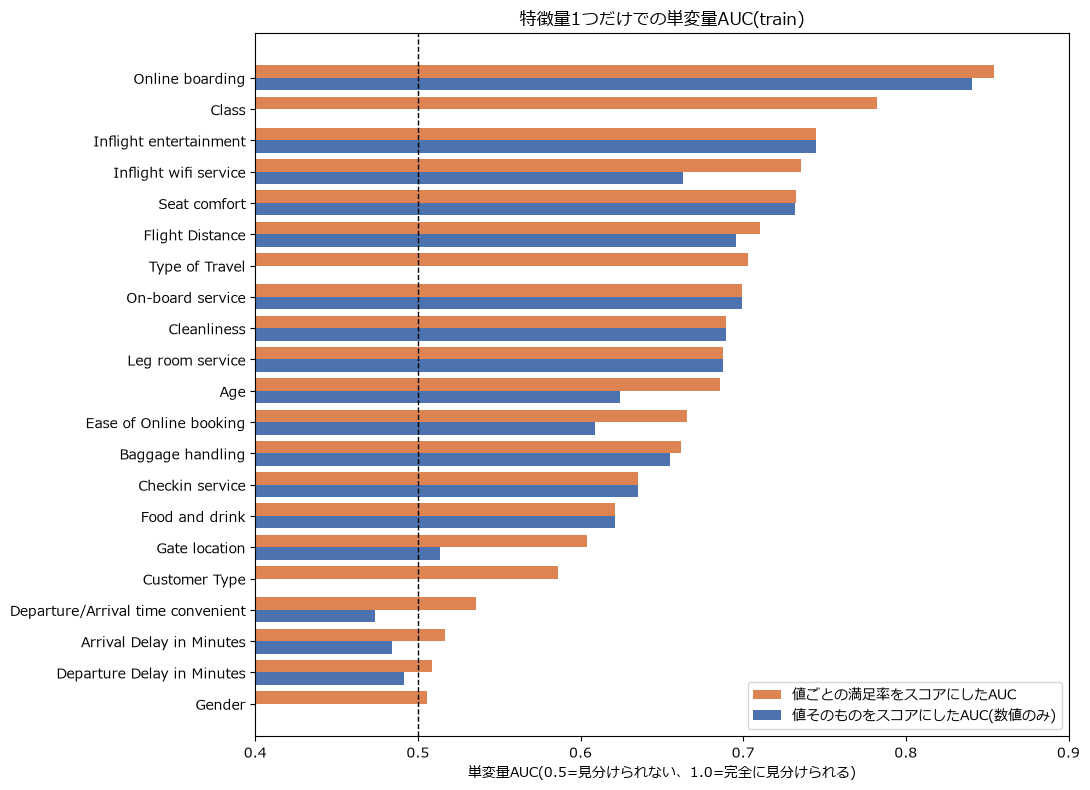

In [8]:
from sklearn.metrics import roc_auc_score

# 単変量AUC: 特徴量1つだけを予測スコアとみなしたときに満足/不満をどれだけ並べ分けられるか
# raw  = 値そのものをスコアにする(「大きいほど満足」の一方向の関係だけを測る)
# rate = 値ごとの満足率をスコアにする(山型・U字型の関係やカテゴリ変数も測れる。連続値は50区間に分ける)
y = train[TARGET]
rows = []
for c in NUM + SVC + CAT:
    x = train[c]
    raw = roc_auc_score(y, x.fillna(-1)) if pd.api.types.is_numeric_dtype(x) else np.nan
    key = (pd.qcut(x, 50, duplicates="drop").astype(str) if x.nunique() > 50 else x.astype(str)).fillna("NA")
    rows.append((c, raw, roc_auc_score(y, y.groupby(key).transform("mean"))))
auc = pd.DataFrame(rows, columns=["feature", "raw", "rate"]).set_index("feature").sort_values("rate")
print(auc.sort_values("rate", ascending=False).round(3))

fig, ax = plt.subplots(figsize=(11, 8))
yy = np.arange(len(auc))
ax.barh(yy + 0.2, auc["rate"], height=0.4, color="#DD8452", label="値ごとの満足率をスコアにしたAUC")
ax.barh(yy - 0.2, auc["raw"], height=0.4, color="#4C72B0", label="値そのものをスコアにしたAUC(数値のみ)")
ax.axvline(0.5, color="k", ls="--", lw=1)
ax.set_yticks(yy, auc.index); ax.set_xlim(0.4, 0.9)
ax.set_xlabel("単変量AUC(0.5=見分けられない、1.0=完全に見分けられる)")
ax.set_title("特徴量1つだけでの単変量AUC(train)")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

#### 考察

**なぜ見たか:** 全体像の確認。どの特徴量が単独で強いかを同じ物差しで比べる。

**見方:** 縦軸=特徴量、横軸=その特徴量だけで満足/不満を並べ分けたときのAUC(0.5=当てずっぽう、1=完璧)。青=値の大小で並べた場合、橙=値ごとの満足率で並べた場合。青と橙の差が大きいほど、値と満足率の関係がまっすぐでない(山型・U字型)。

**発見**
- 上位はOnline boarding 0.854、座席クラス0.782、機内エンタメ0.745、Wi-Fi 0.736。
- 青と橙の差が大きいのはゲートの位置・Wi-Fi・年齢・オンライン予約で、1・2節で山型・U字型が見えた特徴量と一致。
- 単独で弱い特徴量(遅延・性別など)も、組み合わせで効く可能性は残る(5節の距離のように、単独の強さは客層の違いを含む)。

**使い道:** ベースラインで元の特徴量を足す順番(この単変量AUCの高い順)に使った。

## 7. サービス評価0の意味(悪い評価か、未回答・該当なしか)

                                      n0   sat0   sat1   sat5  other0  other1  \
item                                                                            
Inflight entertainment              1020  0.140  0.127  0.671   2.561   2.553   
On-board service                     801  0.147  0.174  0.657   2.897   2.858   
Cleanliness                          945  0.168  0.155  0.630   2.625   2.627   
Checkin service                      929  0.179  0.199  0.610   2.954   2.932   
Seat comfort                         838  0.184  0.174  0.671   2.671   2.637   
Food and drink                      1014  0.219  0.171  0.565   2.669   2.640   
Leg room service                    1693  0.270  0.189  0.615   3.028   2.879   
Departure/Arrival time convenient  25751  0.478  0.506  0.437   3.262   3.006   
Gate location                       1455  0.543  0.514  0.625   3.207   3.193   
Online boarding                     9147  0.620  0.105  0.875   3.216   2.767   
Ease of Online booking      

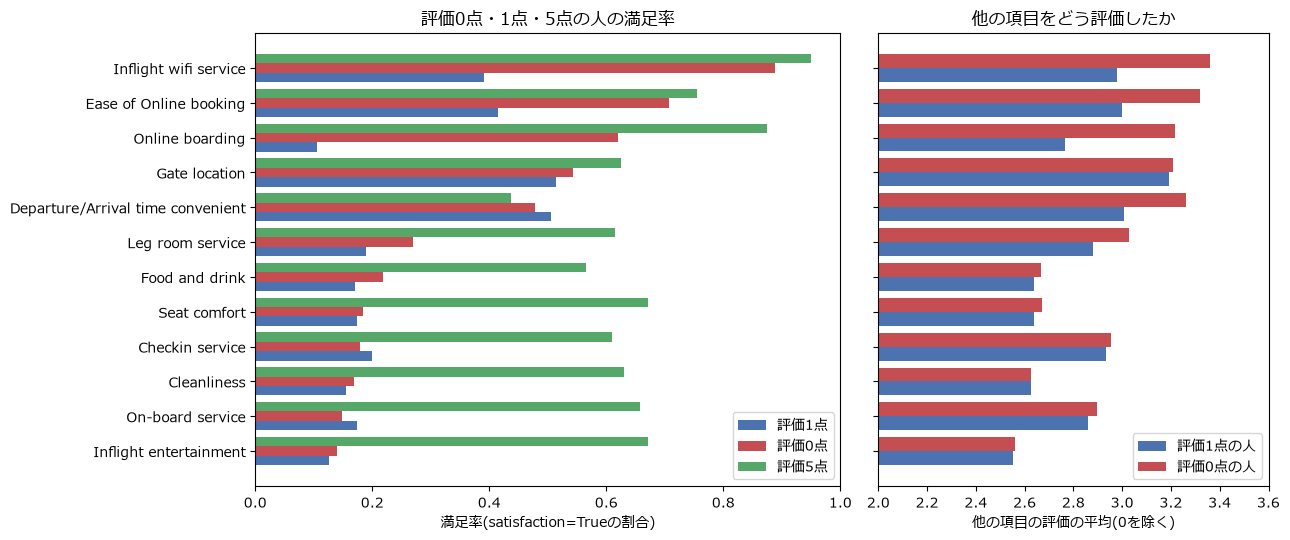

In [9]:
# サービス評価の0は「悪い評価」か「未回答・該当なし」か。0点の人を1点・5点の人と比べる
# 0=悪い評価なら、0点の人は1点の人と似る(満足率が低い・他の項目の評価も低い)はず
items = [c for c in SVC if (train[c] == 0).any()]  # 0が1件も無いBaggage handlingは除く
oof = np.load("data/oof_lgb_forward_n20.npy")  # ベースライン(LightGBM、元の特徴量20個)のOOF予測
yv = train[TARGET].astype(int)
rows = []
for c in items:
    others = [o for o in SVC if o != c]
    other_avg = train[others].replace(0, np.nan).mean(axis=1)  # 他の項目の平均(0は除いて計算)
    z = train[c] == 0
    rows.append({"item": c, "n0": int(z.sum()),
                 "sat0": yv[z].mean(), "sat1": yv[train[c] == 1].mean(), "sat5": yv[train[c] == 5].mean(),
                 "other0": other_avg[z].mean(), "other1": other_avg[train[c] == 1].mean(),
                 "resid0": (yv[z] - oof[z]).mean()})  # 実際の満足率 - 予測確率の平均(0に近いほどモデルが正しく見積もれている)
zero = pd.DataFrame(rows).set_index("item").sort_values("sat0")
print(zero.round(3))

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
yy = np.arange(len(zero))
for off, col, lab, color in [(-0.27, "sat1", "評価1点", "#4C72B0"), (0, "sat0", "評価0点", "#C44E52"),
                              (0.27, "sat5", "評価5点", "#55A868")]:
    ax0.barh(yy + off, zero[col], height=0.27, color=color, label=lab)
ax0.set_yticks(yy, zero.index); ax0.set_xlim(0, 1); ax0.set_xlabel("満足率(satisfaction=Trueの割合)")
ax0.set_title("評価0点・1点・5点の人の満足率"); ax0.legend(loc="lower right")
ax1.barh(yy - 0.2, zero["other1"], height=0.4, color="#4C72B0", label="評価1点の人")
ax1.barh(yy + 0.2, zero["other0"], height=0.4, color="#C44E52", label="評価0点の人")
ax1.set_yticks(yy, []); ax1.set_xlim(2, 3.6); ax1.set_xlabel("他の項目の評価の平均(0を除く)")
ax1.set_title("他の項目をどう評価したか"); ax1.legend(loc="lower right")
fig.tight_layout()
plt.show()

#### 考察

**【仮説】** 2節で、Wi-Fi・オンライン予約は0点の満足率が高かった(U字型)。0点は最低評価ではなく、「使っていない(評価なし)」ではないか。

**【確認】** 項目ごとに、0点・1点・5点の人の満足率と、その人がほかの項目に付けた評価の平均を比べる。
左=項目ごとの満足率(青=1点、赤=0点、緑=5点の人)。赤が青に近ければ0点は「最低評価」、緑に近ければ「評価なし」に近い。右=その人がほかの項目に付けた評価の平均。

**【結果】**
- Wi-Fi・オンライン予約・オンライン搭乗は、0点の満足率(89%・71%・62%)が1点(39%・42%・11%)よりずっと高い。仮説どおり「使っていないので評価なし」の意味と考えられる。
- 一方、座席・食事などは0点と1点の満足率がほぼ同じで、0点は最低評価として使われている。0点の意味は項目で違う。

**【施策】** 項目ごとの0点の印の特徴量は効かなかった。木は「評価≦0.5」の1回の分岐で0点の人を切り出せ、0点の人の満足率もすでに正しく見積もれていた(予測と実際の差が±0.005)。複数の項目にまたがる「0点の個数」は1回の分岐では作れないので試したが、1seedではわずかに効いた(+0.00001)ものの、3通りの分け方で確かめ直すと基準に届かず外した。

## 8. ゲート(Customer Type・Type of Travel・Class)× 変数の満足率ヒートマップ

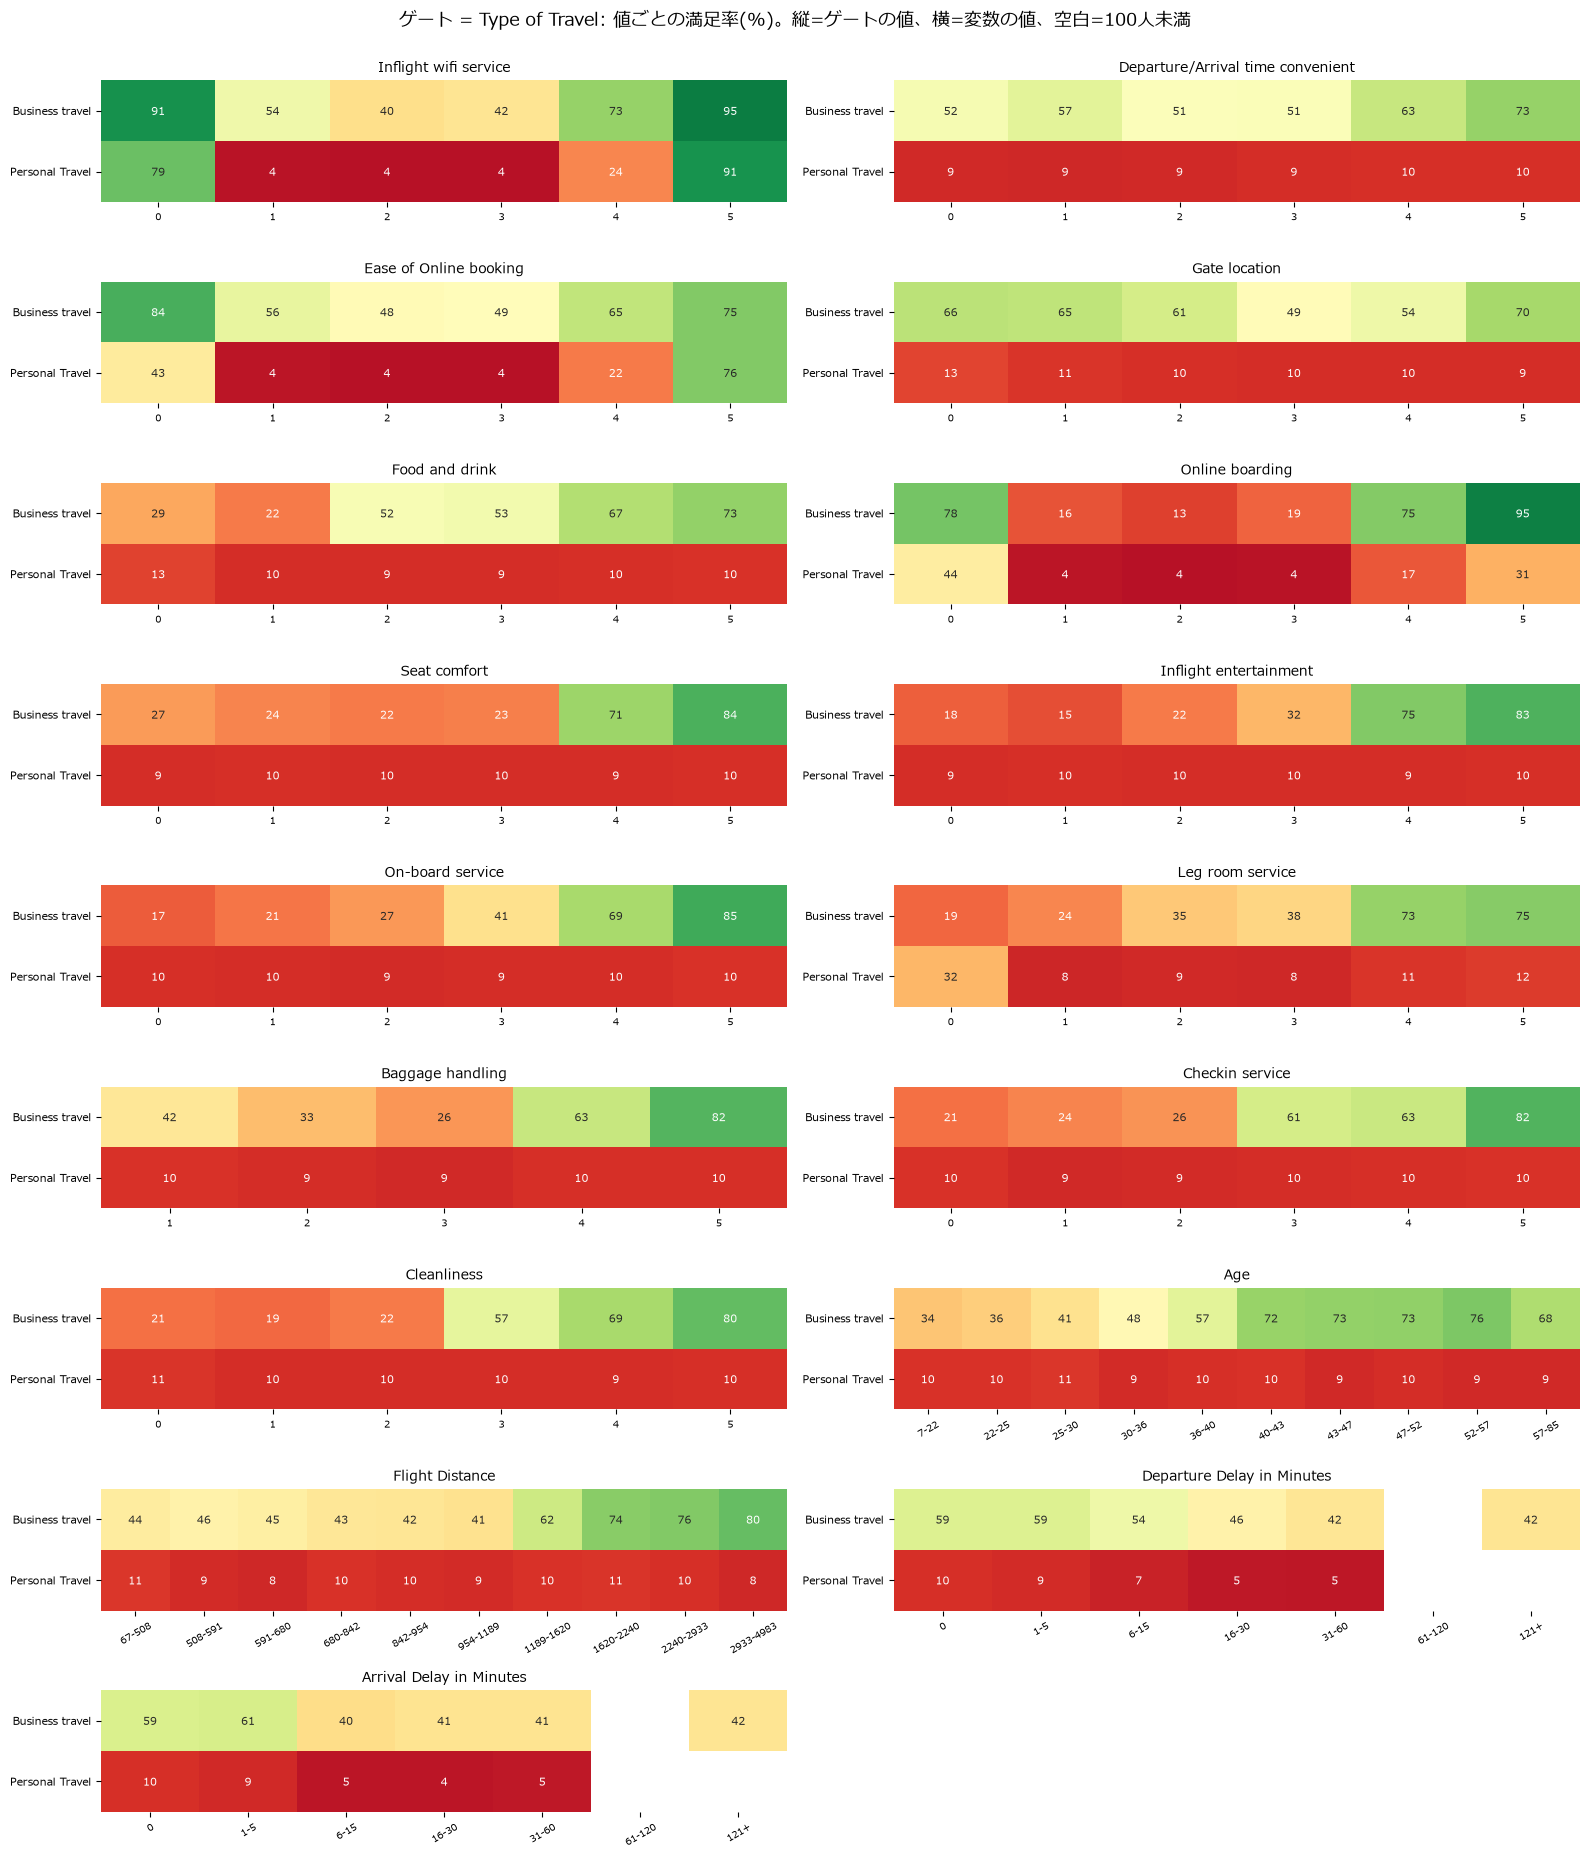

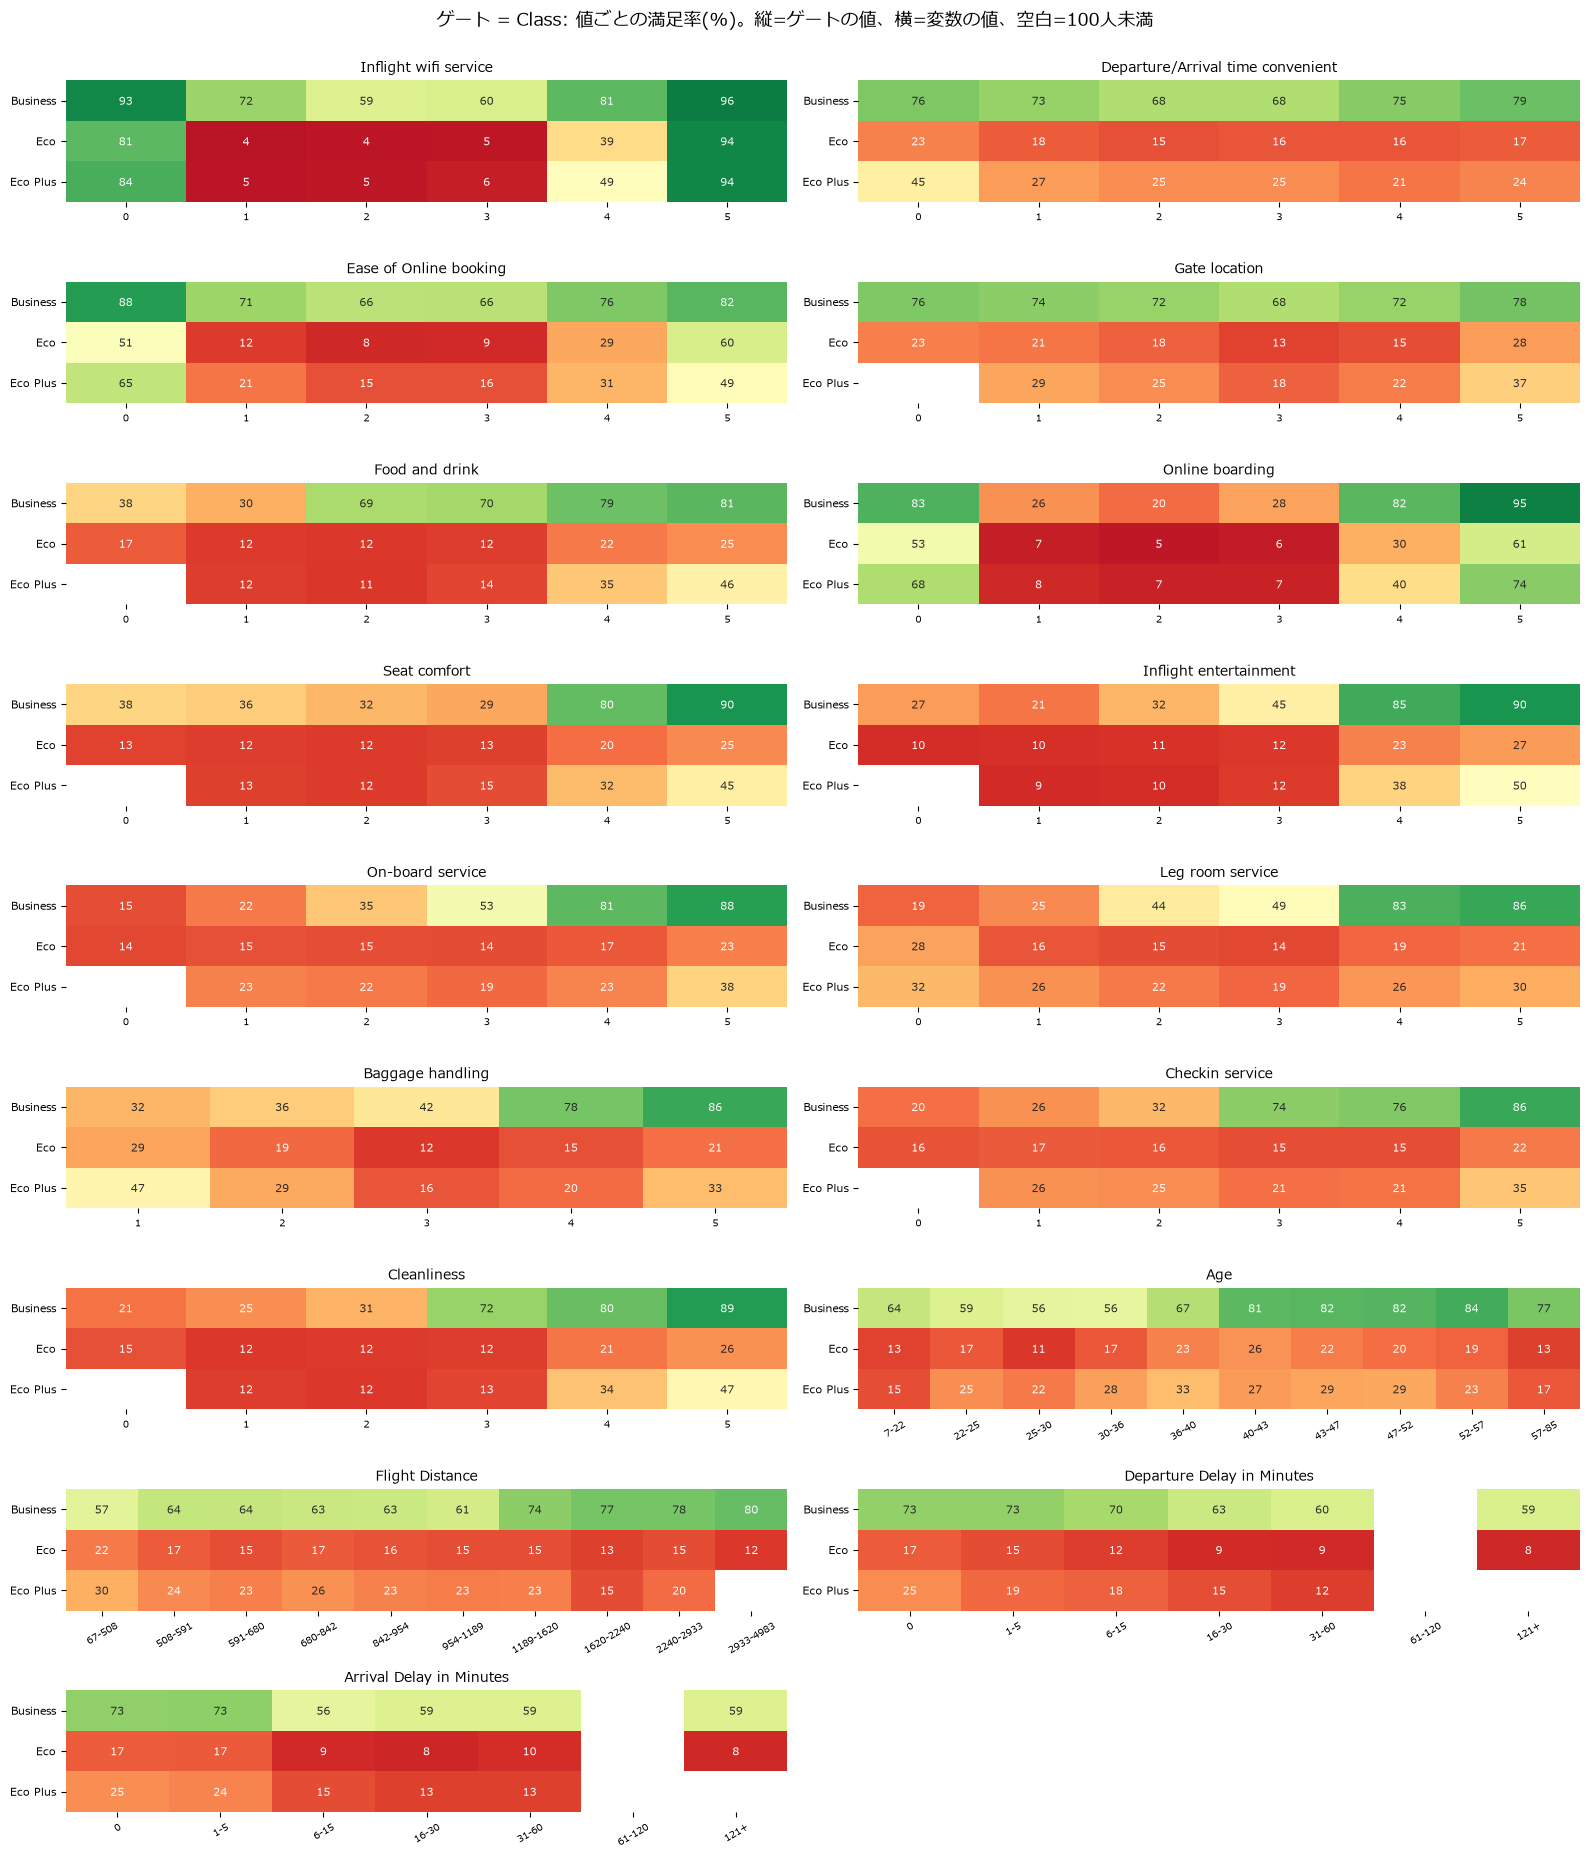

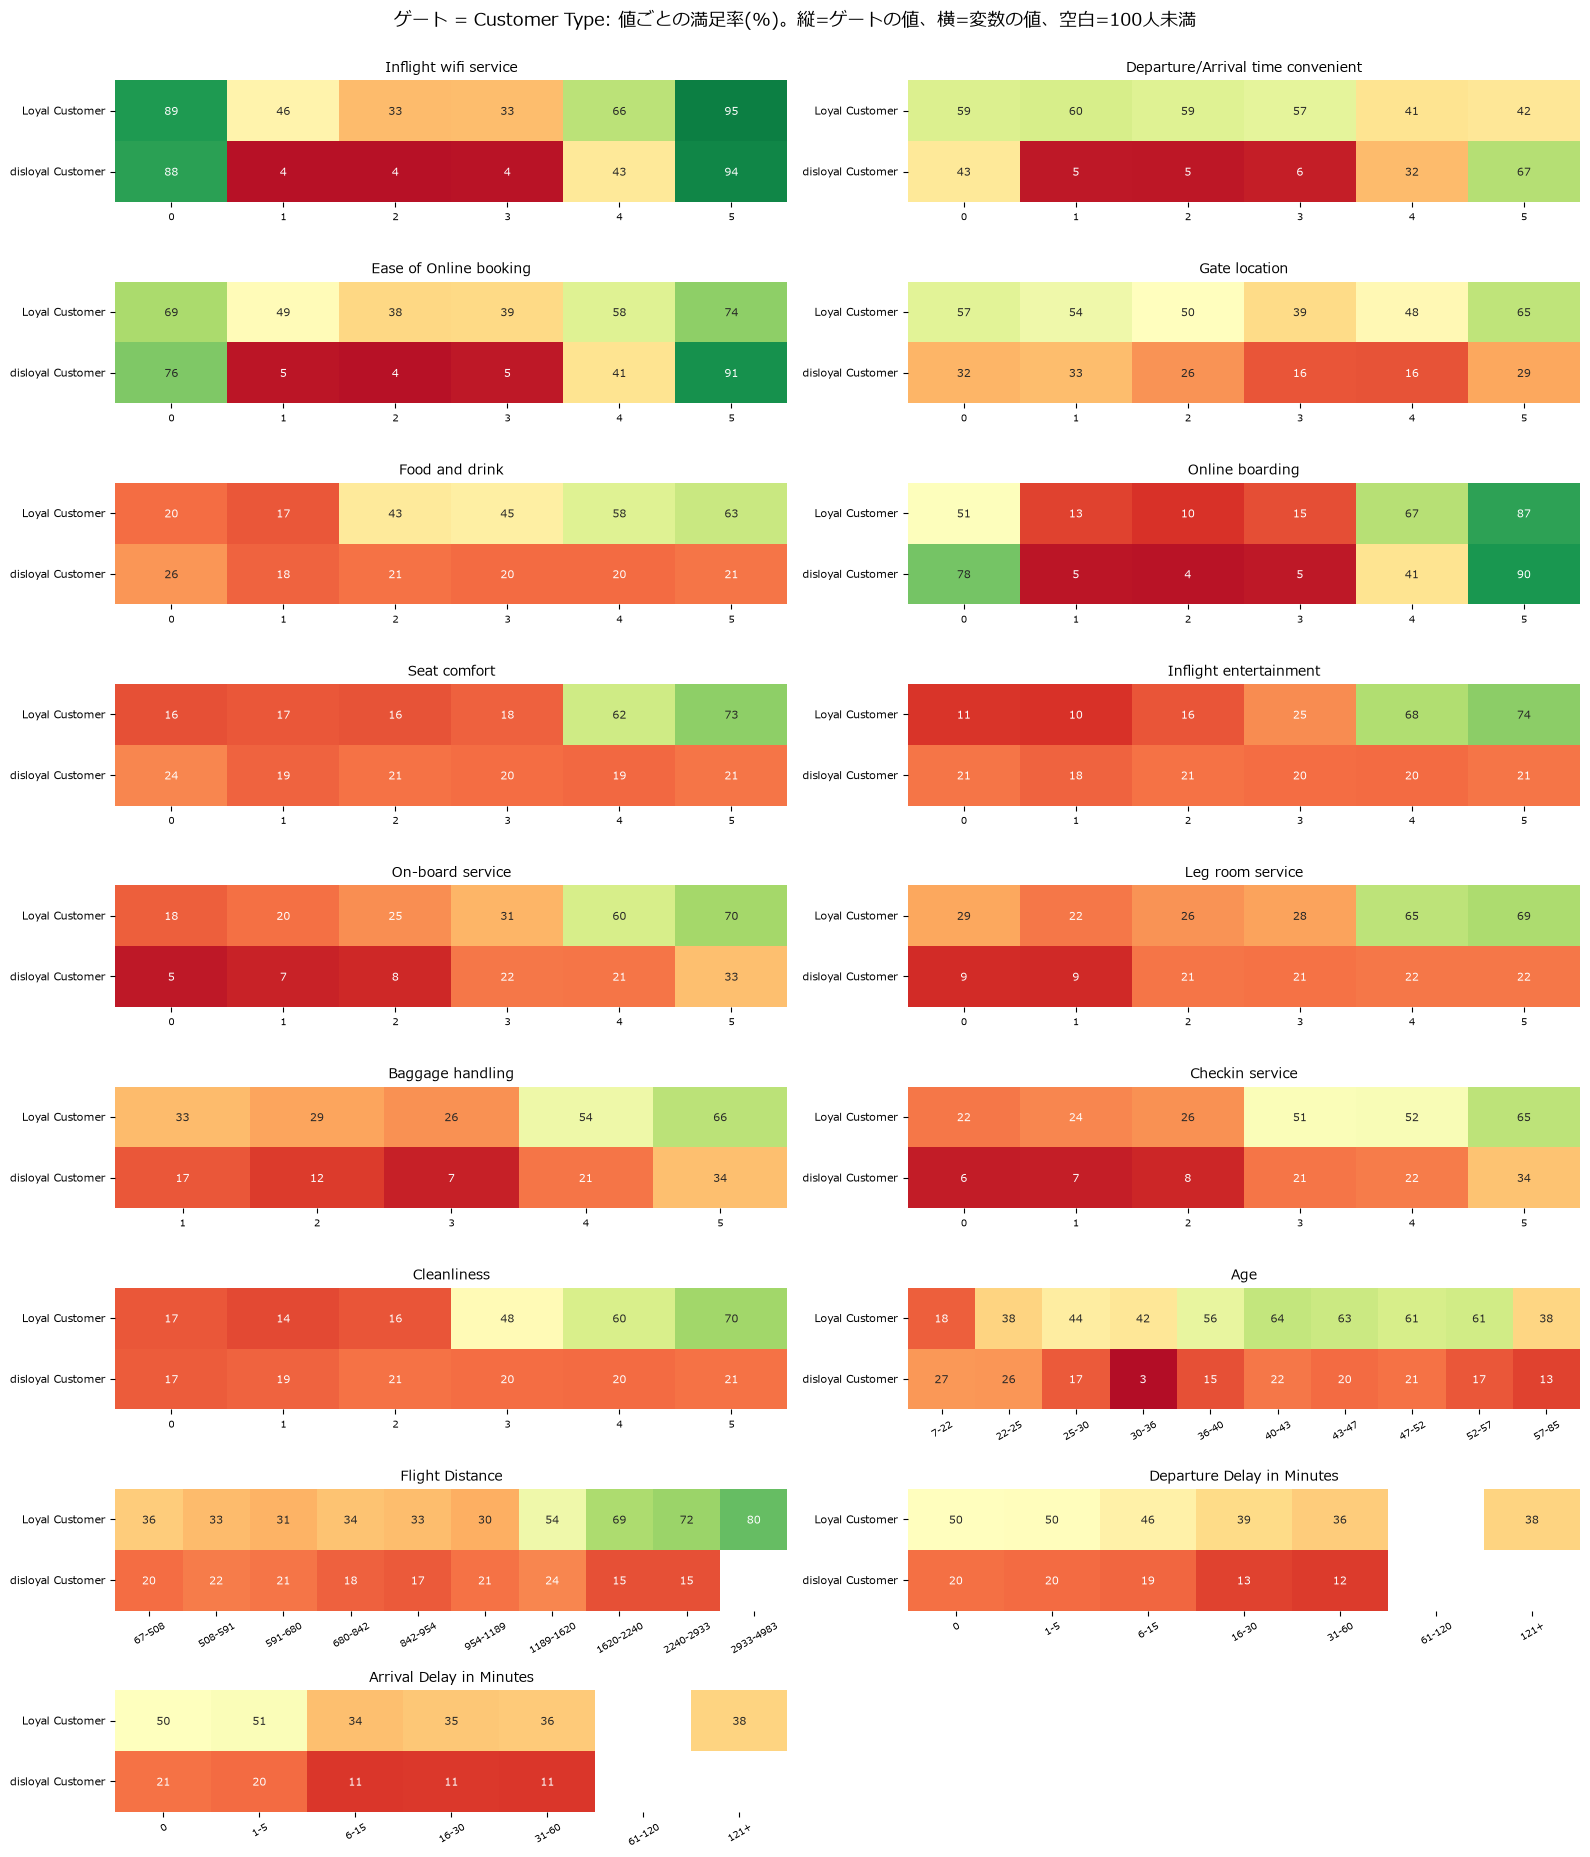

== Type of Travel ==
                               変数  Business travel  Personal Travel  最大-最小
           Inflight entertainment            0.787            0.501  0.285
                     Seat comfort            0.778            0.501  0.276
                 On-board service            0.759            0.509  0.250
                      Cleanliness            0.732            0.502  0.230
                 Baggage handling            0.720            0.509  0.211
                  Online boarding            0.859            0.661  0.198
                              Age            0.672            0.481  0.191
                  Checkin service            0.701            0.514  0.187
                  Flight Distance            0.671            0.499  0.172
                 Leg room service            0.705            0.534  0.171
                   Food and drink            0.645            0.507  0.138
           Ease of Online booking            0.575            0.686  0.110
Depa

In [10]:
# ゲート(Customer Type・Type of Travel・Class)× 変数1つで満足率のヒートマップを描く。
# 縦軸 = ゲートの値、横軸 = 変数の値(連続値は区間に分ける)、色・数字 = そのマスの満足率(%)。
# 同じ列の中で縦に色が大きく違う変数ほど「ゲートの値によって効き方が変わる」= ゲート特徴量の候補
def to_bins(c):
    x = train[c]
    if c in SVC:
        return x
    if c in ("Age", "Flight Distance"):
        return pd.qcut(x, 10, duplicates="drop").map(lambda iv: f"{iv.left:.0f}-{iv.right:.0f}")
    # 遅延は0分が半数以上を占めるので、0分と遅延の長さで区切る
    edges = [-1, 0, 5, 15, 30, 60, 120, np.inf]
    labels = ["0", "1-5", "6-15", "16-30", "31-60", "61-120", "121+"]
    return pd.cut(x.fillna(0), edges, labels=labels)

VARS = SVC + NUM
yv = train[TARGET].astype(int)
for g in ["Type of Travel", "Class", "Customer Type"]:
    fig, axes = plt.subplots(9, 2, figsize=(16, 2.1 * 9))
    for ax, c in zip(axes.flat, VARS):
        b = to_bins(c)
        rate = yv.groupby([train[g], b], observed=True).mean().unstack() * 100
        n = yv.groupby([train[g], b], observed=True).size().unstack()
        rate = rate.where(n >= 100)  # 100人未満のマスは率がぶれるので表示しない
        sns.heatmap(rate, ax=ax, cmap="RdYlGn", vmin=0, vmax=100, annot=True, fmt=".0f", cbar=False,
                    annot_kws={"size": 8})
        ax.set_title(c, fontsize=10)
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.tick_params(axis="x", labelsize=7, rotation=0 if c in SVC else 30)
        ax.tick_params(axis="y", labelsize=8, rotation=0)
    axes.flat[-1].axis("off")
    fig.suptitle(f"ゲート = {g}: 値ごとの満足率(%)。縦=ゲートの値、横=変数の値、空白=100人未満", fontsize=13)
    fig.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

# 数値の要約: ゲートの値ごとに、変数1つで満足・不満をどれだけ見分けられるか(単変量AUC、元の値)
from sklearn.metrics import roc_auc_score
rows = []
for g in ["Type of Travel", "Class", "Customer Type"]:
    for c in VARS:
        r = {"ゲート": g, "変数": c}
        for v in sorted(train[g].unique()):
            m = train[g] == v
            r[v] = roc_auc_score(yv[m], train.loc[m, c].fillna(0))
        vals = [r[v] for v in sorted(train[g].unique())]
        r["最大-最小"] = max(vals) - min(vals)
        rows.append(r)
summary = pd.DataFrame(rows)
for g, d in summary.groupby("ゲート", sort=False):
    print(f"== {g} ==")
    print(d.drop(columns="ゲート").dropna(axis=1, how="all").sort_values("最大-最小", ascending=False).round(3).to_string(index=False))

#### 考察

**【仮説】** 特徴量エンジニアリングで、出張客だけに評価の値を持たせる特徴量(ゲート特徴量)が効いた。座席クラスや常連かどうかでも、評価の効き方が変わるのではないか。

**【確認】** 客の種類(旅行目的・座席クラス・常連かどうか)ごとに、変数の値ごとの満足率を一覧で見る。
小さなヒートマップ1つが変数1つ。縦軸=客の種類、横軸=変数の値、色と数字=満足率(緑ほど高い)。行ごとに色の変わり方が違う変数ほど、客の種類で効き方が変わる。

**【結果】**
- 出張客は機内エンタメ・座席などの評価が4〜5点で満足率70〜85%に上がるが、私用客は点数に関係なく約10%(単変量AUC 0.72〜0.79 対 0.50〜0.51)。
- 常連でない客(ほぼ全員が出張客)では、快適さの評価はどの点数でも満足率約20%で効かない。Wi-Fi・オンライン予約は逆に強く効く。

**【施策】** 効く客層だけ評価の値を持ち、ほかは空欄にするゲート特徴量を作った。ゲートなしの同じ特徴量は効かず、ゲートありとの直接比較で改善したので、効果はゲートによるものと確かめた。「常連かつ出張客」に絞った快適さの特徴量は、SHAP(予測への寄与)で1位になった。